# Program 14: check the hidden features

**What:** check whether the forgotten class is still recognizable inside the network's features.

**How:** freeze the model at the end of the stream. Extract penultimate-layer features for held-out images of the forgotten class plus some other classes. Train a small linear classifier (the probe) on half of them and test it on the other half. Compare with the same probe on a never-trained network and on a retrained-without-that-class model.

**Why:** once you reset a class's output head, output accuracy is trivially 0%, which proves nothing. The probe tests whether the knowledge is truly gone. This can be a contribution of its own.

**Understanding note:** "the model can't output it" and "the model doesn't know it" are different claims. Only the second is real unlearning.

**Done when:** you have one probe-accuracy number per method, and you can say whether program 12's forgotten class survives in the features.

## Where this fits (for a first-time reader)

A ResNet-18 has two parts:

```
image → [ body: 17 conv layers ] → h(x): 512 numbers ("features") → [ head: one linear layer ] → 100 class scores
```

Accuracy (programs 12–13) only looks at the **head's** answer. Unlearning methods often change mostly the head. The body may still compute features that separate the forgotten classes perfectly well, so the knowledge is still *there*, just not *shown*. Later learning can then reconnect the head to it quickly, which is one way relapse can happen.

**The probe** reads the knowledge directly from the body: take the features h(x) of test images of a task's 10 classes, train a simple linear classifier (logistic regression) to tell the 10 classes apart, and measure how often it's right on images it didn't train on. If the features of a "forgotten" task still separate its classes well, that task is not really forgotten.

**What to compare against.** Even a network that never saw a task gives features that separate it somewhat, because general visual features (edges, colours, shapes) help with any class. So a probe number on its own means nothing. We compare three models on the same probe:

| Model | What it is | Role |
|---|---|---|
| **never-trained** | random weights | the floor: what random features give |
| **retrain** | DER++ on the same stream, but the forgotten tasks are **never learned** | the ideal: what "never saw it" looks like |
| **unlearned (12)** | program 12's final model | the one being tested |

If the unlearned model's probe on forgotten tasks is **about the retrain model's**, the knowledge is gone. If it is **clearly higher**, the forgotten tasks survive inside the features.

## 1. Setup

- `stream`: program 12's run to check (its final model and its saved table).
- The retrain model is trained here with the same DER++ settings as program 12 (about 8 minutes for the 5 kept tasks of `task15_seed0`), and saved, so a second run skips it.
- `probe_folds`: 5-fold cross-validation on the 1,000 test images of each task (100 per class). Each fold trains on 800 images and tests on 200.

In [1]:
import gc, sys, time
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "common").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))  # lets us import common/

# Reload the shared code, so edits to common/ are picked up even without restarting the kernel.
import importlib
import common.utils, common.data, common.models, common.train, common.derpp, common.badteacher, common.features, common.metrics
for module in (common.utils, common.data, common.models, common.train, common.derpp, common.badteacher, common.features, common.metrics):
    importlib.reload(module)

import matplotlib.pyplot as plt
import numpy as np
import torch

from common.data import N_TASKS, SplitCIFAR100, task_classes
from common.derpp import DERBuffer, train_one_epoch_derpp
from common.features import features_of, probe_accuracy
from common.metrics import item_view
from common.models import resnet18_cifar
from common.stream import load_stream, stream_to_str
from common.utils import RESULTS_DIR, get_device, log_run, set_seed

SETTINGS = {
    "stream": "task15_seed0",
    "seed": 0,
    "workers": 2,
    # DER++ for the retrain model (same as program 12)
    "epochs": 5, "lr": 0.03, "batch_size": 32,
    "buffer_size": 2000, "replay_batch": 32, "alpha": 0.5, "beta": 0.5,
    "probe_folds": 5,
}
device = get_device()
stream = load_stream(RESULTS_DIR / "streams" / f"{SETTINGS['stream']}.json")["requests"]
FORGOTTEN = [i for k, i in stream if k == "U"]
KEPT = [i for k, i in stream if k == "L" and i not in FORGOTTEN]
print("stream:", stream_to_str(stream))
print("forgotten tasks:", FORGOTTEN, "  kept tasks:", KEPT)

unlearned_path = RESULTS_DIR / f"12_{SETTINGS['stream']}_model.pt"
if not unlearned_path.exists():
    raise FileNotFoundError(f"{unlearned_path} not found. Run program 12 with stream = '{SETTINGS['stream']}' first.")

stream: L5 → L2 → L3 → L4 → U5 → L9 → L0 → U3 → U2 → L8 → U8 → L7 → L6 → L1 → U4
forgotten tasks: [5, 3, 2, 8, 4]   kept tasks: [9, 0, 7, 6, 1]


## 2. The retrain model: the same stream without the forgotten tasks

The retrain model follows the same stream, but skips every `L` of a task that is forgotten later, and every `U`. So it learns only the kept tasks, in the same order, with the same DER++ settings. This is what a perfect unlearning method should be equivalent to: as if the forgotten data had never been there.

If `results/14_retrain_<stream>_model.pt` already exists, it is loaded instead of trained.

In [2]:
data = SplitCIFAR100(seed=SETTINGS["seed"], batch_size=SETTINGS["batch_size"], num_workers=SETTINGS["workers"])
retrain_path = RESULTS_DIR / f"14_retrain_{SETTINGS['stream']}_model.pt"

if retrain_path.exists():
    print(f"{retrain_path.name} exists: loading it (delete the file to train again)")
else:
    set_seed(SETTINGS["seed"])
    model = resnet18_cifar(num_classes=100).to(device)
    scaler = torch.amp.GradScaler(enabled=device.type == "cuda")
    buffer = DERBuffer(SETTINGS["buffer_size"], dataset=data.train_set)
    start = time.time()
    for task in KEPT:
        loader = data.get_task_loader_with_index(task)
        optimizer = torch.optim.SGD(model.parameters(), lr=SETTINGS["lr"], momentum=0.9)
        for epoch in range(SETTINGS["epochs"]):
            losses, train_acc = train_one_epoch_derpp(model, loader, optimizer, buffer, scaler, device,
                                                      alpha=SETTINGS["alpha"], beta=SETTINGS["beta"],
                                                      replay_batch=SETTINGS["replay_batch"])
        del loader, optimizer
        gc.collect()
        print(f"retrain: learned task {task}, train acc {train_acc*100:.1f}%  ({time.time()-start:.0f}s)")
    torch.save(model.state_dict(), retrain_path)
    del model, buffer
    gc.collect()
    torch.cuda.empty_cache()
    print("saved", retrain_path.name)

retrain: learned task 9, train acc 68.8%  (62s)


retrain: learned task 0, train acc 65.2%  (123s)


retrain: learned task 7, train acc 79.5%  (183s)


retrain: learned task 6, train acc 80.1%  (242s)


retrain: learned task 1, train acc 87.0%  (301s)


saved 14_retrain_task15_seed0_model.pt


## 3. Features of every test image, for each model

Each model is loaded alone, run once over the 10,000 test images to get h(x) (512 numbers per image), and deleted. We keep only the features (20 MB per model) and the head's task-IL accuracy per task (what the model *says*, for comparison).

In [3]:
X_test = torch.stack([data.test_set[i][0] for i in range(len(data.test_set))]).to(device)
Y_test = np.array(data.test_set.targets)
del data
gc.collect()


def load_model(kind):
    torch.manual_seed(SETTINGS["seed"])          # fixes the never-trained network's random weights
    model = resnet18_cifar(num_classes=100).to(device)
    if kind != "never-trained":
        path = {"retrain": retrain_path, "unlearned (12)": unlearned_path}[kind]
        model.load_state_dict(torch.load(path, map_location=device))
    return model.eval()


@torch.no_grad()
def head_task_il(model):
    # The head's task-IL accuracy on each task (choose among the task's 10 outputs).
    logits = torch.cat([model(X_test[i:i + 1000]) for i in range(0, len(X_test), 1000)]).float().cpu().numpy()
    out = []
    for t in range(N_TASKS):
        idx = (Y_test // 10) == t
        pred = logits[idx][:, task_classes(t)].argmax(1) + 10 * t
        out.append(float((pred == Y_test[idx]).mean()))
    return np.array(out)


FEATS, HEAD = {}, {}
for kind in ["never-trained", "retrain", "unlearned (12)"]:
    model = load_model(kind)
    FEATS[kind] = features_of(model, X_test).numpy()
    HEAD[kind] = head_task_il(model)
    del model
    torch.cuda.empty_cache()
    print(f"{kind:>15}: features {FEATS[kind].shape}")
del X_test
torch.cuda.empty_cache()

  never-trained: features (10000, 512)


        retrain: features (10000, 512)


 unlearned (12): features (10000, 512)


## 4. Probe every task with every model

For each task: the features of its 1,000 test images, 10 classes, 5-fold cross-validated logistic regression. Chance is 10%.

The table also shows the **head's** task-IL accuracy (what the model *says*) next to the **probe** (what its features *know*). For a forgotten task in the unlearned model, the interesting case is: head near 10%, probe high.

In [4]:
probe = {kind: np.zeros(N_TASKS) for kind in FEATS}
for t in range(N_TASKS):
    idx = (Y_test // 10) == t
    for kind in FEATS:
        probe[kind][t], _ = probe_accuracy(FEATS[kind][idx], Y_test[idx], folds=SETTINGS["probe_folds"], seed=SETTINGS["seed"])

status = {t: "forgotten" if t in FORGOTTEN else "kept" for t in range(N_TASKS)}
print(f"{'task':>5} {'status':>10} | {'probe: never-trained':>20} {'retrain':>8} {'unlearned':>10} | "
      f"{'head: retrain':>13} {'unlearned':>10}")
for t in range(N_TASKS):
    print(f"{t:5d} {status[t]:>10} | {probe['never-trained'][t]*100:19.1f}% {probe['retrain'][t]*100:7.1f}% "
          f"{probe['unlearned (12)'][t]*100:9.1f}% | {HEAD['retrain'][t]*100:12.1f}% {HEAD['unlearned (12)'][t]*100:9.1f}%")

print("\naverages (%):")
print(f"{'':>22} {'probe never':>11} {'probe retrain':>13} {'probe unlearned':>15} {'head unlearned':>14}")
for name, tasks in [("forgotten tasks", FORGOTTEN), ("kept tasks", KEPT)]:
    print(f"{name:>22} {probe['never-trained'][tasks].mean()*100:11.1f} {probe['retrain'][tasks].mean()*100:13.1f} "
          f"{probe['unlearned (12)'][tasks].mean()*100:15.1f} {HEAD['unlearned (12)'][tasks].mean()*100:14.1f}")

 task     status | probe: never-trained  retrain  unlearned | head: retrain  unlearned
    0       kept |                34.5%    71.8%      73.2% |         70.6%      69.9%
    1       kept |                47.8%    85.5%      86.3% |         82.0%      86.3%
    2  forgotten |                49.6%    77.8%      80.2% |          5.6%      28.6%
    3  forgotten |                39.0%    63.8%      69.0% |         11.0%      22.2%
    4  forgotten |                37.7%    72.5%      78.9% |          7.0%      13.0%
    5  forgotten |                43.9%    71.6%      73.2% |          8.2%      23.6%
    6       kept |                28.4%    78.7%      81.5% |         79.0%      77.9%
    7       kept |                41.6%    79.4%      84.7% |         77.8%      85.9%
    8  forgotten |                33.3%    69.6%      78.6% |         16.5%      52.3%
    9       kept |                40.8%    77.7%      80.1% |         75.4%      77.8%

averages (%):
                       probe

## 5. The picture

For each task, three bars (probe on never-trained, retrain, unlearned) and a black dot (the unlearned model's **head** accuracy). Forgotten tasks are shaded. For a forgotten task:
- dot low and red bar close to the green one → really forgotten;
- dot low but red bar **well above** green → the head forgot, the features did not.

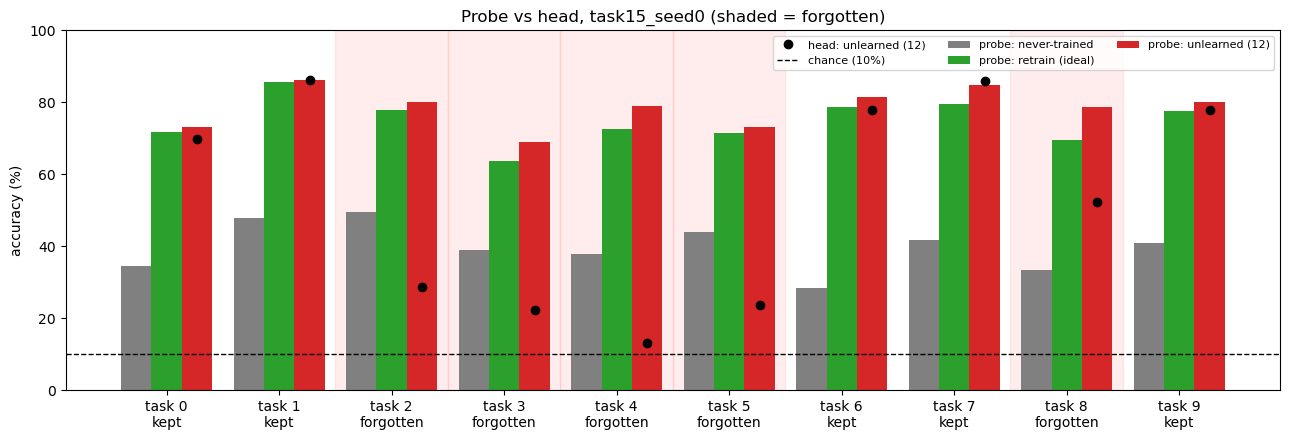

In [5]:
x = np.arange(N_TASKS)
w = 0.27
fig, ax = plt.subplots(figsize=(13, 4.5))
for t in FORGOTTEN:
    ax.axvspan(t - 0.5, t + 0.5, color="red", alpha=0.07)
ax.bar(x - w, probe["never-trained"] * 100, w, label="probe: never-trained", color="gray")
ax.bar(x, probe["retrain"] * 100, w, label="probe: retrain (ideal)", color="tab:green")
ax.bar(x + w, probe["unlearned (12)"] * 100, w, label="probe: unlearned (12)", color="tab:red")
ax.plot(x + w, HEAD["unlearned (12)"] * 100, "ko", label="head: unlearned (12)")
ax.axhline(10, color="black", ls="--", lw=1, label="chance (10%)")
ax.set_xticks(x, [f"task {t}\n{status[t]}" for t in x])
ax.set(ylabel="accuracy (%)", ylim=(0, 100), title=f"Probe vs head, {SETTINGS['stream']} (shaded = forgotten)")
ax.legend(fontsize=8, ncol=3)
fig.tight_layout()
fig.savefig(RESULTS_DIR / f"14_probe_{SETTINGS['stream']}.png", dpi=120)
plt.show()

## 6. One number per method, and the verdict

The roadmap asks for one probe number per method: the average probe accuracy on the **forgotten** tasks. The "survival gap" is the unlearned model's number minus the retrain model's. A gap of 0 means the features look as if the tasks were never learned. With 5 tasks and 5-fold CV, differences of a couple of points are noise.

In [6]:
one = {kind: float(probe[kind][FORGOTTEN].mean()) for kind in probe}
gap = one["unlearned (12)"] - one["retrain"]
for kind, v in one.items():
    print(f"{kind:>15}: probe on forgotten tasks {v*100:5.1f}%")
print(f"\nsurvival gap (unlearned - retrain): {gap*100:+.1f} points")
print(f"head of the unlearned model on forgotten tasks: {HEAD['unlearned (12)'][FORGOTTEN].mean()*100:.1f}% (chance 10%)")
if gap > 0.05:
    print("-> the forgotten tasks SURVIVE in the features: the head forgot, the body did not.")
elif gap > 0.02:
    print("-> a small trace survives in the features.")
else:
    print("-> the features look like the tasks were never learned.")

  never-trained: probe on forgotten tasks  40.7%
        retrain: probe on forgotten tasks  71.1%
 unlearned (12): probe on forgotten tasks  76.0%

survival gap (unlearned - retrain): +4.9 points
head of the unlearned model on forgotten tasks: 27.9% (chance 10%)
-> a small trace survives in the features.


## 7. Log the run

In [7]:
log_run("14_feature_probe", SETTINGS,
        {"forgotten": FORGOTTEN, "kept": KEPT,
         "probe": {k: [round(float(v), 4) for v in a] for k, a in probe.items()},
         "head_task_il": {k: [round(float(v), 4) for v in a] for k, a in HEAD.items()},
         "probe_forgotten_mean": {k: round(v, 4) for k, v in one.items()},
         "survival_gap": round(gap, 4)})
print("logged to", RESULTS_DIR / "runs.jsonl")

logged to /run/media/adarsh/AAE039EFE039C1FD/std/research/results/runs.jsonl


## Lab notebook

*Write one paragraph here: what you saw, and what surprised you.*

Questions to answer in it:
1. How well do random features (never-trained) separate a task? Why is that the floor and not 10%?
2. For the forgotten tasks: head accuracy vs probe accuracy in the unlearned model. Did BadTeacher change the head, the body, or both?
3. Survival gap: do program 12's forgotten tasks survive in the features?
4. The retrain model never saw the forgotten tasks, yet its probe on them is above the never-trained one. Why?
5. If the features still separate a forgotten task, how could later learning bring its head accuracy back (relapse)? How does that connect to program 13's Relapse numbers?